# Diagnostic et préparation automatiques
**Cartomize · Sources 1.3.0**

Durée indicative : 25 minutes.

Ce cours reproduit le parcours attendu après téléchargement : sélectionner les bandes et la zone, vérifier la couverture, décider si une mosaïque suffit, puis préparer les données et lancer une analyse. Les cellules utilisent les mêmes fonctions que les formulaires de bureau.

Toutes les données sont **simulées**. La première zone présente des lacunes malgré les deux scènes ; une seconde zone pédagogique est entièrement couverte par leur réunion. Modifier la zone est ici un exercice de comparaison, pas une solution pour masquer les lacunes d’une étude réelle.

Installer l’environnement depuis la racine du dépôt suivant le [guide du parcours](../README.md), puis exécuter toutes les cellules. Qt n’est pas nécessaire.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from shapely.geometry import box
from IPython.display import display

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "course.py").is_file() or (p / "tutorials/course.py").is_file())
root = root if (root / "course.py").is_file() else root / "tutorials"
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import cartomize as cm
from course import demo, run_directory, CRS

out = run_directory("13_diagnostic_automatique")
data = demo(out / "data")
scenes = cm.load_scenes_manifest(data["scenes"])
print("Version Cartomize :", cm.__version__)
display(pd.DataFrame([
    {"scène": s.scene_id, "date": s.acquired, "bandes": len(s.bands)}
    for s in scenes
]))

Version Cartomize : 1.3.0


,scène,date,bandes
0,synthetic_A,2026-01-01,7
1,synthetic_B,2026-01-01,7


## 1. Choisir les règles une seule fois

Les deux scènes ont une date commune et des réflectances déjà calibrées. Nous demandons les bandes rouge et proche infrarouge, une grille projetée à 30 m et les centres des pixels dans la zone. Les données simulées n’ont pas de masque de nuages : ce choix est déclaré explicitement. Pour un produit réel, conserver les masques QA/SCL et les métadonnées nécessaires.

Le même dictionnaire de paramètres sera transmis au diagnostic et à la préparation pour garder des résultats comparables.

In [2]:
parameters = dict(
    band_order=["red", "nir"],
    target_crs=CRS,
    resolution=30,
    resampling="nearest",
    mask_clouds=False,  # Données simulées sans masque de qualité.
    all_touched=False,
)
audit = cm.audit_imagery(
    scenes, out / "diagnostic_zone_initiale",
    aoi=data["aoi"], coverage_threshold=100.0, **parameters,
)
summary = pd.DataFrame(
    [{"scène": item["id"], "emprise_%": item["footprint_percent"],
      "présence_%": item["present_percent"], "utilisable_%": item["usable_percent"]}
     for item in audit.report["scenes"]]
    + [{"scène": "Réunion des scènes", "emprise_%": audit.report["footprint_percent"],
        "présence_%": audit.report["present_percent"],
        "utilisable_%": audit.report["usable_percent"]}]
)
display(summary.round(2))
print("Décision :", audit.report["recommended_action"])
assert audit.report["footprint_percent"] == 100.0
assert 0 < audit.report["usable_percent"] < 100.0
assert audit.report["recommended_action"] == "additional_scenes"

,scène,emprise_%,présence_%,utilisable_%
0,synthetic_A,63.56,54.89,54.89
1,synthetic_B,56.78,48.73,48.73
2,Réunion des scènes,100.00,83.28,83.28


Décision : additional_scenes


## 2. Lire les lacunes avant de calculer

Une emprise géométrique complète ne garantit pas des valeurs utilisables. Le diagnostic distingue : 0, données utilisables ; 1, hors emprise ; 2, données absentes ; 3, données rejetées par la qualité. Le code 255 est hors zone.

Dans cet exemple, les coins du paysage simulé contiennent des NoData. Ajouter les deux scènes couvre l’emprise, mais ne comble pas ces lacunes. Sur une étude réelle, conserver la zone d’étude et rechercher des acquisitions compatibles, ou documenter une couverture partielle selon le protocole retenu.

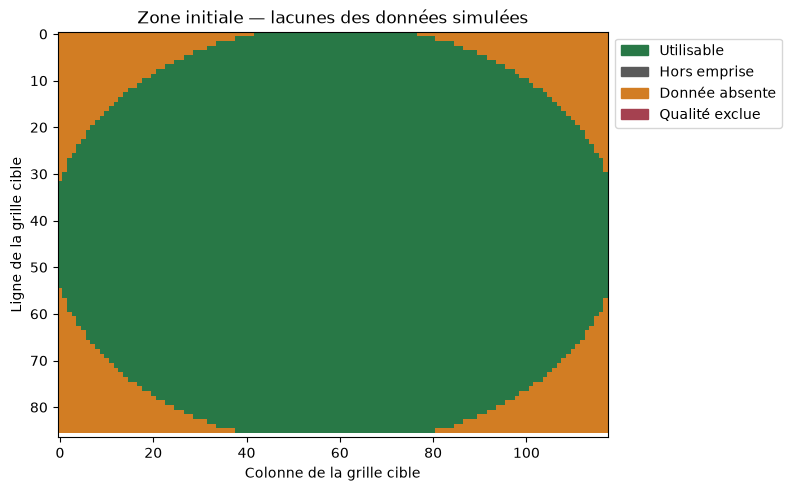

In [3]:
with rasterio.open(audit.gaps) as src:
    gaps = src.read(1, masked=True)
assert np.count_nonzero(gaps.filled(255) == 2) > 0

colors = ["#287846", "#5a5a5a", "#d27d23", "#a54150"]
labels = ["Utilisable", "Hors emprise", "Donnée absente", "Qualité exclue"]
fig, ax = plt.subplots(figsize=(8, 4.8), layout="constrained")
ax.imshow(gaps, cmap=ListedColormap(colors),
          norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], 4), interpolation="nearest")
ax.set(title="Zone initiale — lacunes des données simulées",
       xlabel="Colonne de la grille cible", ylabel="Ligne de la grille cible")
ax.legend(handles=[Patch(color=color, label=label)
                   for color, label in zip(colors, labels)],
          loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 3. Comparer avec une zone réellement couverte par deux scènes

La zone pédagogique suivante traverse la limite de couverture de chaque scène. Aucune scène seule ne suffit, mais leur réunion atteint 100 %. Une mosaïque est donc justifiée pour **cette nouvelle zone**. Le seuil de 100 % porte sur les cellules sélectionnées de la grille, pas sur une mesure fractionnaire de surface.

In [4]:
study_area = gpd.GeoDataFrame(
    {"name": ["Zone pédagogique couverte"]},
    geometry=[box(301200, 9498050, 303000, 9499100)],
    crs=CRS,
)
ready = cm.audit_imagery(
    scenes, out / "diagnostic_zone_couverte",
    aoi=study_area, coverage_threshold=100.0, **parameters,
)
display(pd.DataFrame([
    {"scène": item["id"], "utilisable_%": item["usable_percent"]}
    for item in ready.report["scenes"]
]).round(2))
print("Couverture réunie :", ready.report["usable_percent"], "%")
print("Décision :", ready.report["recommended_action"])
assert all(item["usable_percent"] < 100.0 for item in ready.report["scenes"])
assert ready.report["usable_percent"] == 100.0
assert ready.report["recommended_action"] == "mosaic"
assert set(ready.report["recommended_scene_ids"]) == {s.scene_id for s in scenes}

,scène,utilisable_%
0,synthetic_A,66.67
1,synthetic_B,73.33


Couverture réunie : 100.0 %
Décision : mosaic


## 4. Appliquer la décision et préparer le multibande

La décision a trois états explicites. Une scène suffisante peut être conservée seule ; une mosaïque utilise les scènes proposées ; une couverture insuffisante interrompt cette chaîne exigeant 100 %. La priorité de recouvrement est déclarée et un même pixel spectral provient toujours d’une seule scène.

Le rapport de préparation, le multibande scientifique et l’index de provenance des scènes sont conservés ensemble. Une composition RVB étirée n’est pas utilisée comme entrée du NDVI.

In [5]:
def prepare_from_audit(diagnostic, sources, aoi, destination, parameters):
    action = diagnostic.report["recommended_action"]
    if action == "additional_scenes":
        raise ValueError("Couverture insuffisante : consulter les lacunes et rechercher des scènes.")
    if action not in {"single_scene", "mosaic"}:
        raise ValueError(f"Décision inconnue : {action}")
    selected_ids = set(diagnostic.report["recommended_scene_ids"])
    selected = [scene for scene in sources if scene.scene_id in selected_ids]
    return cm.prepare_imagery(
        selected, destination, aoi=aoi, overlap="first", **parameters
    )

prepared = prepare_from_audit(
    ready, scenes, study_area, out / "multibande.tif", parameters
)
assert prepared.report["coverage_percent"] == 100.0
assert prepared.path.is_file() and prepared.source_index.is_file()
print("Produit :", prepared.path.name)
print("Bandes :", prepared.bands)
print("Couverture :", prepared.report["coverage_percent"], "%")

Produit : multibande.tif
Bandes : ('red', 'nir')
Couverture : 100.0 %


## 5. Calculer le NDVI et mesurer chaque zone

Le NDVI utilise les rôles de bandes du multibande. Les statistiques zonales appliquent par défaut les facteurs et décalages du raster. Ici, le NDVI est déjà une valeur physique.

La couverture rapporte le nombre de pixels valides à **tous les pixels de la zone**, y compris la partie éventuellement hors raster. Le préfixe évite de confondre les résultats avec des champs existants. Les moyennes ne sont pas pondérées par les surfaces fractionnaires des pixels.

In [6]:
ndvi = out / "ndvi.tif"
cm.spectral_indices(prepared.path, ndvi, ["NDVI"])
zones = gpd.GeoDataFrame(
    {"name": ["Ouest", "Est"]},
    geometry=[
        box(301200, 9498050, 302100, 9499100),
        box(302100, 9498050, 303000, 9499100),
    ], crs=CRS,
)
statistics = cm.raster.zonal_stats(
    ndvi, zones, value_mode="physical", prefix="ndvi_", include_coverage=True
)
display(statistics[["name", "ndvi_count", "ndvi_mean",
                    "ndvi_zone_pixels", "ndvi_raster_pixels",
                    "ndvi_coverage_percent"]].round(4))
np.testing.assert_allclose(statistics["ndvi_coverage_percent"], 100.0)
assert statistics["ndvi_count"].sum() == ready.report["aoi_pixels"]
statistics.drop(columns="geometry").to_csv(out / "statistiques_ndvi.csv", index=False)

,name,ndvi_count,ndvi_mean,ndvi_zone_pixels,ndvi_raster_pixels,ndvi_coverage_percent
0,Ouest,1050,0.2625,1050,1050,100.0
1,Est,1050,0.1963,1050,1050,100.0


## 6. Retrouver les mêmes outils dans la fenêtre et dans les chaînes

Dans **Prétraitement multispectral**, choisir les bandes et la zone, cliquer sur **Diagnostiquer la couverture**, consulter les cartes puis appliquer la proposition. Dans **Traitements raster**, les statistiques zonales proposent les mêmes choix de valeurs et de couverture. Le registre des chaînes expose ces fonctions sans réécrire leur calcul.

In [7]:
catalog = pd.DataFrame(cm.operation_catalog())
expected = {"imagery.audit", "prepare", "raster.zonal_stats"}
# Le registre peut grandir : vérifier les fonctions utiles, pas un total figé.
assert expected <= set(catalog["id"])
display(catalog.loc[catalog["id"].isin(expected), ["id", "label", "output"]])
print("Livrables :", sorted(p.name for p in out.iterdir() if p.is_file()))

,id,label,output
24,raster.zonal_stats,Statistiques zonales,vector
37,prepare,Prétraitement multispectral,raster
38,imagery.audit,Diagnostic de couverture des images,document


Livrables : ['multibande.json', 'multibande.tif', 'multibande_source_index.tif', 'ndvi.tif', 'statistiques_ndvi.csv']


## Exercice corrigé

**Question.** Pourquoi ne faut-il pas lancer la préparation de la première zone et annoncer une couverture complète après la mosaïque ?

**Réponse.** La réunion des emprises atteint 100 %, mais les bandes contiennent des pixels invalides. Le rapport propose donc `additional_scenes`. La fonction de décision ci-dessus refuse cette préparation dans une chaîne exigeant 100 % et renvoie vers le diagnostic. Une acceptation de couverture partielle serait un autre choix méthodologique, à déclarer avec un seuil explicite.

**À adapter à l’étude.** Remplacer le manifeste et la zone, vérifier le capteur, les dates, les bandes, les masques, le SCR et la résolution. Un mélange de dates ne doit pas être autorisé simplement pour supprimer une erreur. Le diagnostic mesure la disponibilité selon ces paramètres ; il ne valide ni la représentativité temporelle ni la qualité scientifique des références.

Voir le [contrat du diagnostic](../../docs/IMAGERY_AUDIT.md), les [statistiques zonales](../../docs/RASTER_STATISTICS.md) et l’[inventaire des procédures expertes](../../docs/EXPERT_PROCEDURES.md).